parent: Preselection_v6

In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack
from LoadData import *
from SystHelper import *
from beeps import *

Welcome to JupyROOT 6.28/00


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]
PART = sys.argv[4]

DUMP_PKL = False
DRAW_SR = True
RUN_SIDEBAND_MET = False
RUN_SIDEBAND_MASS = False
RUN_SIDEBAND_PT = False
DUMP_SIDEBAND_MET_PKL = False
DUMP_SIDEBAND_MASS_PKL = False
DUMP_SIDEBAND_PT_PKL = False
RUN_BTAG = True
EXPORT_VARIABLE = False

# # for dev
# ERA = "em18"
# DATE = "20230722jer_18"
# # INPUTDIR = "/eos/user/h/hkwon/SWAN_projects/Zpeak/20230622jer_18/Presel"
# # INPUTDIR = "/eos/user/h/hkwon/SWAN_projects/Zpeak/20230722jer_18/Presel/DUMP"
# INPUTDIR = "/eos/user/h/hkwon/Run2/Preselection/20230722jer/Presel/DUMP"


# Load data

In [3]:
dic_df_raw, dic_nested_shape_sys = get_dic_raw_sys(ERA, INPUTDIR, "TR")

In [4]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTUp': 88.29, 'TTDown': 88.29, 'TThdampUp': 88.29, 'TThdampDown': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 12.82, 'WZ': 5.23, 'WZQQ': 6.42, 'ZZ': 0.6008, 'WWW': 0.0072, 'WWZ': 0.1707, 'HWW': 0.31, 'H': 2.78, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300

# Draw

In [5]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
# #     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
    "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
    "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
    "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
    "U_pre": [14, 0, 660, "U [GeV]"],
#     "HT_pre": [14, 0, 660, "HT [GeV]"],
    "JZB_pre": [14, 80, 660, "JZB"],
    "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
    "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
    "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
    "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# # #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# # #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# # #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
    "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# # #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# # #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
    "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    "nbjetflav_pre": [7, 0, 7, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
    "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
    
# partition
if PART=="one":
    dic_variable={
        "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
        "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
        "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
        "U_pre": [14, 0, 660, "U [GeV]"],
        "JZB_pre": [14, 80, 660, "JZB"],   
    }  
#     if "em" in ERA:
#         dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
#         dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]    
if PART=="two":
    dic_variable={
    "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
    "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
    "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
    "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
    "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    "nbjetflav_pre": [7, 0, 7, "N bjetflav"],     
    "njet_pre": [10, 0, 10, "N jet"],    
    }      
    
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'PuppiMET_pre': [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]'], 'mass_pre': [22, 100, 1000, 'M_{ll} [GeV]'], 'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'], 'Zpt_pre': [25, 0, 500, 'p_{T}(ll) [GeV]'], 'MT_pre': [27, 0, 550, 'M_{T} [GeV]'], 'MT2_pre': [17, 0, 350, 'M_{T2} [GeV]'], 'U_pre': [14, 0, 660, 'U [GeV]'], 'JZB_pre': [14, 80, 660, 'JZB'], 'dPhill_pre': [17, 0, 3.4, '#Delta#phi(l,l)'], 'dPhilMET_pre': [17, 0, 3.4, '#Delta#phi(l,p_{T}^{miss})'], 'dRll_pre': [30, 0, 6, '#DeltaR(l,l)'], 'dPhillMET_pre': [17, 0, 3.4, '#Delta#phi(ll,p_{T}^{miss})'], 'eta_lead_pre': [15, -3, 3, '#eta(l_{lead})'], 'eta_trail_pre': [15, -3, 3, '#eta(l_{trail})'], 'PuppiMET_phi_pre': [20, -4, 4, 'Puppi p_{T}^{miss} #phi(l_{trail})'], 'nbjetflav_pre': [7, 0, 7, 'N bjetflav'], 'njet_pre': [10, 0, 10, 'N jet']}
[('PuppiMET_pre', [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]']), ('mass_pre', [22, 100, 1000, 'M_{ll} [GeV]']), ('pt_lead_pre', [15, 80, 660,

In [6]:
from multiprocessing import Pool

def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
#     year = ERA.replace('mm', '')
#     year = year.replace('ee', '')
#     year = year.replace('em', '')
    
    os.system("mkdir -p "+out_dir)
    os.system("mkdir -p "+out_dir+"/sys")
    os.system("mkdir -p "+out_dir+"/AN")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    threshold = 1
    if region=='SR':
        if not 'phi' in variable and not 'eta' in variable:
    #         if not 'eta' in variable:
            threshold = 0.3
        if "PuppiMET_pre" in variable:
            threshold = 0.5
        if "nbjet" in variable:
            threshold = -0.2  
    # draw plot with syst
#     dic_sys_sqr = draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, dic_variable[variable], region, threshold)
    file_prefix = out_dir
    sys_list = get_sys_list()
    dic_sys_sqr = get_dic_sys("Zp-2500_CH-345", ERA, dic_df_raw, dic_nested_shape_sys, sys_list, variable, dic_variable[variable], region, threshold, file_prefix, file_str=query_str)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr)      
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=out_dir+"/AN/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([-0.05506342,  5.7940181 ,  0.81804518,  5.62687914,  2.88824544,
        9.64958985,  6.33430532,  8.4204337 ,  8.2744632 ,  7.04860095,
       10.37162507, 12.54855839,  7.29259367,  7.57630386,  5.40523498,
        6.26026008,  0.        ]), 'puweightDown': array([ -0.60097804,  -5.12716288,  -2.43683065,  -5.34305602,
        -4.55943895,  -9.11651392,  -5.96960889,  -8.91938974,
        -8.61565227,  -7.12838277, -10.814842  , -12.05409355,
        -7.28891233,  -6.34087833,  -4.74585276,  -5.57389886,
         0.        ]), 'l1prefiringUp': array([1.8433543 , 1.84385987, 1.76105632, 1.49953188, 1.1922714 ,
       0.94823721, 0.78956695, 0.73598723, 0.7452333 , 0.87926425,
       1.12243554, 1.51966929, 2.07829391, 2.78570852, 3.41119185,
       2.66154017, 0.        ]), 'l1prefiringDown': array([-1.93328608, -1.93844149, -1.85122783, -1.57579007, -1.25214405,
       -0.9971388 , -0.83078768, -0.77479774, -0.78450419, -0.92485478,
       -1.17857315, -1.598120

       0.00000000e+00])}
{'scaleUp': array([1.3433785 , 1.815112  , 4.33399506, 2.54815927, 1.59866209,
       0.5392998 , 1.28298561, 1.65880981, 1.47223877, 1.03864333,
       3.00852104, 2.70658909, 4.60289836, 7.7113111 , 6.6952375 ,
       4.47819191, 0.        ]), 'scaleDown': array([4.25290735, 2.1831212 , 1.93292316, 2.47605959, 3.1253717 ,
       3.530408  , 0.8242185 , 0.70860612, 1.41001038, 0.8712542 ,
       1.70689755, 2.30111891, 4.57871317, 8.04824664, 7.47581273,
       5.25940753, 0.        ]), 'puweightUp': array([  0.        ,  33.5706457 ,   0.66919792,  31.6617689 ,
         8.34196174,  93.11458429,  40.12342391,  70.90370369,
        68.46674132,  49.68277534, 107.57060662, 157.46631773,
        53.18192241,  57.40038018,  29.21656515,  39.19085624,
         0.        ]), 'puweightDown': array([  0.36420659,  26.28779919,   5.9381436 ,  28.54824765,
        20.7884835 ,  83.11082601,  35.63623033,  79.55551339,
        74.22946411,  50.81384098, 116.96080751, 14

         0.        ])}
{'puweightUp': array([ 0.00000000e+00,  2.93226441e-02, -1.88494773e-01,  8.79203083e-02,
        1.31268155e+00,  1.86141560e+00,  1.65917095e+00,  7.96562391e-01,
        5.03200457e+00,  4.72664989e+00,  7.93124797e+00,  8.80285274e+00,
        1.21301394e+01,  1.03087374e+01,  1.86398927e+01,  1.51658972e+01,
        4.32419386e+00,  6.93649098e+00,  1.43817102e+00,  1.55356444e+00,
        5.03348995e-01,  5.41555337e-01,  2.30954477e-01,  2.73373953e-01,
        1.76725280e-02,  1.09831737e-01,  4.37680700e-02, -1.48236397e-02,
       -8.75283877e-06,  0.00000000e+00]), 'puweightDown': array([ 0.00000000e+00, -1.57347897e-02,  1.26894997e-01, -1.98838537e-01,
       -1.21326596e+00, -1.63094010e+00, -1.86860092e+00, -1.25344383e+00,
       -5.26928375e+00, -5.22897996e+00, -8.30565909e+00, -8.28793406e+00,
       -1.12888210e+01, -1.01286019e+01, -1.74588662e+01, -1.56048837e+01,
       -5.36569528e+00, -6.02746285e+00, -1.32989932e+00, -2.14613420e+00,
   

        0.00000000e+00,  0.00000000e+00])}
{'scaleUp': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.95987491e-02,
       8.44655046e-03, 2.11398997e-01, 5.90188956e-02, 5.56116462e-01,
       1.19561698e+00, 3.29198787e+00, 4.14427067e+00, 5.53676394e+00,
       7.11594566e+00, 6.59254652e+00, 1.46114720e+01, 9.19068583e+00,
       6.70650653e+00, 1.60252826e+00, 8.99811165e-02, 1.17893413e-01,
       4.68371279e-03, 1.08894929e-02, 1.08338988e-02, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'scaleDown': array([0.00000000e+00, 0.00000000e+00, 1.18613800e-02, 4.50342320e-03,
       2.94799411e-02, 9.16429403e-02, 6.91764710e-01, 2.69175474e-01,
       1.69418757e+00, 2.01264644e+00, 5.37557279e+00, 4.49627016e+00,
       7.53278717e+00, 1.07142355e+01, 1.23054873e+01, 2.02652036e+01,
       3.15500001e+00, 5.73066551e-01, 2.22622551e-01, 9.63312564e-02,
       5.68175349e-02, 1.14585633e-02, 

       1.65680664e-13, 0.00000000e+00])}
{'scaleUp': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.95987491e-02,
       8.44655046e-03, 2.11398997e-01, 5.90188956e-02, 5.56116462e-01,
       1.19561698e+00, 3.29198787e+00, 4.14427067e+00, 5.53676394e+00,
       7.11594566e+00, 6.59254652e+00, 1.46114720e+01, 9.19068583e+00,
       6.70650653e+00, 1.60252826e+00, 8.99811165e-02, 1.17893413e-01,
       4.68371279e-03, 1.08894929e-02, 1.08338988e-02, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'scaleDown': array([0.00000000e+00, 0.00000000e+00, 1.18613800e-02, 4.50342320e-03,
       2.94799411e-02, 9.16429403e-02, 6.91764710e-01, 2.69175474e-01,
       1.69418757e+00, 2.01264644e+00, 5.37557279e+00, 4.49627016e+00,
       7.53278717e+00, 1.07142355e+01, 1.23054873e+01, 2.02652036e+01,
       3.15500001e+00, 5.73066551e-01, 2.22622551e-01, 9.63312564e-02,
       5.68175349e-02, 1.14585633e-02, 8.

...

       -2.8970964 ,  0.        ])}
{'scaleUp': array([ 5.14605384,  1.46282483,  2.17187367,  0.64199803,  1.75216194,
        1.28483339,  2.1419081 ,  0.3512162 ,  3.74795074,  2.23365155,
        3.58084944,  2.08494404,  6.24262399,  2.07101288, 10.49755132,
        2.66138452,  0.        ]), 'scaleDown': array([2.28275484, 0.14964031, 4.92415774, 1.77755095, 0.21990333,
       3.73953102, 6.73461211, 5.59879229, 1.71502144, 0.09570326,
       5.84455106, 3.29412891, 3.72529166, 0.36156874, 7.58811742,
       8.39316756, 0.        ]), 'puweightUp': array([3.60448294e-03, 3.33254973e+01, 3.23895809e+01, 5.10593160e+01,
       2.69431601e+00, 2.10471190e+01, 6.64173193e+00, 9.79776092e+00,
       1.72261142e+01, 7.68763780e+01, 5.29527164e+01, 7.71483400e+01,
       1.28807606e+02, 1.50476839e+02, 2.05344762e+02, 5.70110200e+01,
       0.00000000e+00]), 'puweightDown': array([  0.58864319,  34.73990672,  35.49571962,  36.26091451,
         5.93270419,  32.40911702,  12.79412968,  13.

         0.        ])}
here {'scaleUp': array([ 5.14605384,  1.46282483,  2.17187367,  0.64199803,  1.75216194,
        1.28483339,  2.1419081 ,  0.3512162 ,  3.74795074,  2.23365155,
        3.58084944,  2.08494404,  6.24262399,  2.07101288, 10.49755132,
        2.66138452,  0.        ]), 'scaleDown': array([2.28275484, 0.14964031, 4.92415774, 1.77755095, 0.21990333,
       3.73953102, 6.73461211, 5.59879229, 1.71502144, 0.09570326,
       5.84455106, 3.29412891, 3.72529166, 0.36156874, 7.58811742,
       8.39316756, 0.        ]), 'puweightUp': array([3.60448294e-03, 3.33254973e+01, 3.23895809e+01, 5.10593160e+01,
       2.69431601e+00, 2.10471190e+01, 6.64173193e+00, 9.79776092e+00,
       1.72261142e+01, 7.68763780e+01, 5.29527164e+01, 7.71483400e+01,
       1.28807606e+02, 1.50476839e+02, 2.05344762e+02, 5.70110200e+01,
       0.00000000e+00]), 'puweightDown': array([  0.58864319,  34.73990672,  35.49571962,  36.26091451,
         5.93270419,  32.40911702,  12.79412968,  13.4606868

        0.00000000e+00,  0.00000000e+00])}
{'scaleUp': array([2.68157258e+02, 3.60656673e+01, 3.67537900e+00, 1.41484480e+00,
       3.20072240e-02, 1.19295159e-03, 1.09176012e-02, 0.00000000e+00,
       8.71337346e-04, 1.86657623e-03, 0.00000000e+00, 1.17800851e-03,
       0.00000000e+00, 0.00000000e+00]), 'scaleDown': array([2.79028302e+02, 4.26142326e+01, 4.25356670e+00, 7.56028867e-01,
       8.03608950e-02, 1.84744680e-02, 2.02568010e-02, 1.10176015e-02,
       4.06741569e-03, 0.00000000e+00, 2.01742685e-06, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightUp': array([2.80119723e+03, 1.18515979e+03, 1.06129520e+02, 1.87190907e+01,
       1.67551388e-01, 5.58693663e-02, 1.49316656e+00, 2.50102585e-01,
       5.61373322e-02, 1.27049623e-01, 1.42026996e-01, 1.51637450e-04,
       0.00000000e+00, 3.08624090e-04]), 'puweightDown': array([3.05050375e+03, 1.09063370e+03, 1.08428269e+02, 9.08215479e+00,
       4.98725220e-01, 0.00000000e+00, 1.74641582e+00, 6.49815638e-01

       1.89198156e+00, 1.92961269e+00])}
here {'scaleUp': array([2.68157258e+02, 3.60656673e+01, 3.67537900e+00, 1.41484480e+00,
       3.20072240e-02, 1.19295159e-03, 1.09176012e-02, 0.00000000e+00,
       8.71337346e-04, 1.86657623e-03, 0.00000000e+00, 1.17800851e-03,
       0.00000000e+00, 0.00000000e+00]), 'scaleDown': array([2.79028302e+02, 4.26142326e+01, 4.25356670e+00, 7.56028867e-01,
       8.03608950e-02, 1.84744680e-02, 2.02568010e-02, 1.10176015e-02,
       4.06741569e-03, 0.00000000e+00, 2.01742685e-06, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightUp': array([2.80119723e+03, 1.18515979e+03, 1.06129520e+02, 1.87190907e+01,
       1.67551388e-01, 5.58693663e-02, 1.49316656e+00, 2.50102585e-01,
       5.61373322e-02, 1.27049623e-01, 1.42026996e-01, 1.51637450e-04,
       0.00000000e+00, 3.08624090e-04]), 'puweightDown': array([3.05050375e+03, 1.09063370e+03, 1.08428269e+02, 9.08215479e+00,
       4.98725220e-01, 0.00000000e+00, 1.74641582e+00, 6.49815638e

Info in <TCanvas::Print>: pdf file 20230722jer_18/Presel/DRAW/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_MT2_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230722jer_18/Presel/DRAW/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_U_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230722jer_18/Presel/DRAW/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230722jer_18/Presel/DRAW/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230722jer_18/Presel/DRAW/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_dPhill_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230722jer_18/Presel/DRAW/em

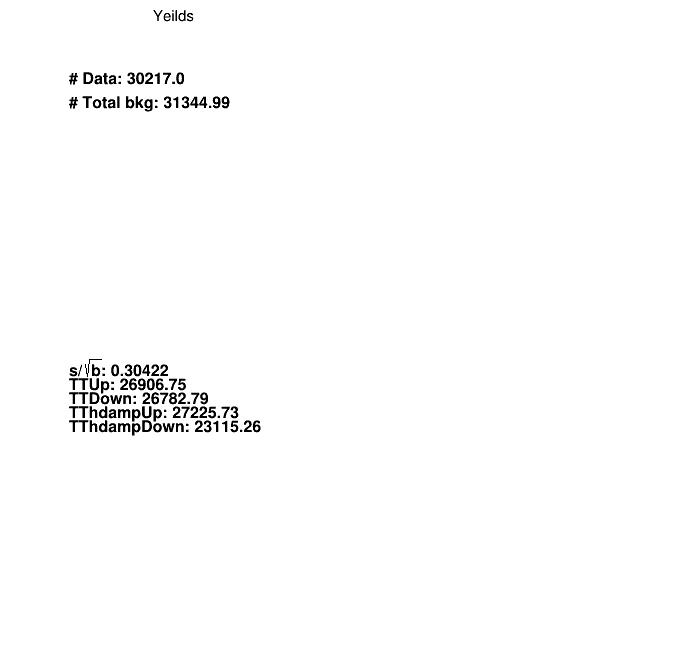

In [7]:
query_str = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"

if DRAW_SR:
    region = "SR"
    out_dir = DATE+"/Presel/DRAW/"+ERA+"/"+region
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=out_dir+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=out_dir+"/pie_"+query_str)

In [8]:
# ###### wotop ######
# dic_variable={
#     "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#     "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"], 
# }
# os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wotop")

# for variable, r in dic_variable.items():
#     if not "Puppi" in variable:
#         threshold = 0.3
#     else:
#         threshold = 0.5
#     hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
#     hist=HistStack(dic_df_raw, variable, "weighthdampUp", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_hdampUp"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weighthdampDown", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_hdampDown"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weightPSUp", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_UEUp"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weightPSDown", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_UEDown"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "wotop", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/norm_"+query_str, blind_from=threshold) 
# hist.get_yeilds()
# hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/pie_"+query_str)  

In [9]:
# ###### wobsf ######
# dic_variable={
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
# }
# os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wobsf")

# for variable, r in dic_variable.items():
#     if not "Puppi" in variable:
#         threshold = 0.3
#     else:
#         threshold = 0.5
#     hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
#     hist=HistStack(dic_df_raw, variable, "wobsf", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wobsf/norm_"+query_str, blind_from=threshold) 

# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230722jer_18/Presel/DRAW/em18/SR/sig_eff.pdf has been created


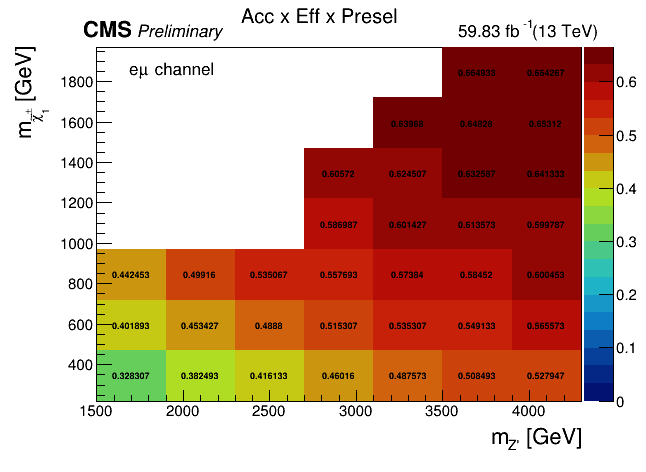

In [10]:
str_channel, str_lumi = HistStack.get_str_lumi_channel(ERA, ERA)

Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# # missing bin by hand
# h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
# h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz text")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+str_channel+" channel}}")

latex1=rt.TLatex()
latex1.DrawLatexNDC(0.71, 0.92, "#font[42]{#scale[0.8]{"+str_lumi+" fb^{-1}(13 TeV)}}");
latex1.DrawLatexNDC(0.13, 0.92, "#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}");
 
c1.Draw()
c1.SaveAs(out_dir+"/sig_eff.pdf")